In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from estimating_ud.config import results_dir

TABLES = results_dir("tables")


In [ ]:
df = pd.read_csv(TABLES / 'trinuc_constraint.csv')

stats = df.groupby(['Region'])['Constraint'].agg(['mean', 'sem']).unstack()
stats.to_csv(TABLES / 'trinuc_constraint_mean_sem.csv')
stats

      Region        
mean  cds               0.624297
      distalIG          0.053091
      introns3UTR       0.387324
      introns5UTR       0.381858
      intronsAR         0.106581
      introns_nonUTR    0.200553
      proximal3IG       0.144786
      proximal5IG       0.144977
sem   cds               0.007552
      distalIG          0.006126
      introns3UTR       0.005895
      introns5UTR       0.007800
      intronsAR         0.011109
      introns_nonUTR    0.007820
      proximal3IG       0.009927
      proximal5IG       0.007639
dtype: float64

In [ ]:
df = pd.read_csv(TABLES / 'singlent_constraint.csv')

stats = df.groupby(['Region'])['Constraint'].agg(['mean', 'sem']).unstack()
stats.to_csv(TABLES / 'singlent_constraint_mean_sem.csv')
stats

      Region        
mean  cds               0.557254
      distalIG          0.079002
      introns3UTR       0.197537
      introns5UTR       0.211655
      intronsAR         0.105468
      introns_nonUTR    0.206034
      proximal3IG       0.132015
      proximal5IG       0.131824
sem   cds               0.009054
      distalIG          0.006916
      introns3UTR       0.007843
      introns5UTR       0.009443
      intronsAR         0.006351
      introns_nonUTR    0.008362
      proximal3IG       0.007967
      proximal5IG       0.008361
dtype: float64

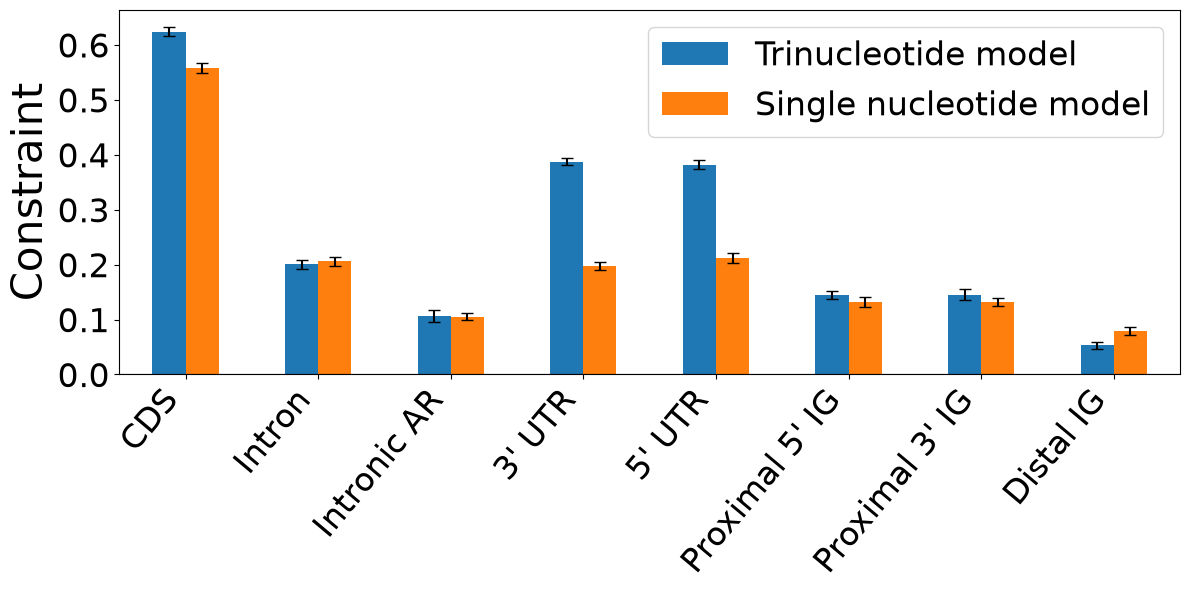

In [ ]:
def region_mean_sem(path):
    df = pd.read_csv(path)
    return df.groupby('Region')['Constraint'].agg(['mean', 'sem'])

trinuc = region_mean_sem(TABLES / 'trinuc_constraint.csv')
singlent = region_mean_sem(TABLES / 'singlent_constraint.csv')

mean_df = pd.DataFrame({'Trinucleotide model': trinuc['mean'], 'Single nucleotide model': singlent['mean']})
err_df = pd.DataFrame({'Trinucleotide model': trinuc['sem'], 'Single nucleotide model': singlent['sem']})

name_map = dict(zip(
    ["cds", "introns_nonUTR", "intronsAR", "introns3UTR", "introns5UTR",
     "proximal5IG", "proximal3IG", "distalIG"],
    ["CDS", "Intron", "Intronic AR", "3' UTR", "5' UTR",
     "Proximal 5' IG", "Proximal 3' IG", "Distal IG"]
))
mean_df = mean_df.loc[list(name_map)]
err_df = err_df.loc[list(name_map)]

labelfontsize = 30
ticksfontsize = 24
legendfontsize = 24

ax = mean_df.plot(
    kind='bar',
    yerr=err_df,
    capsize=4,
    color=['#1f77b4', '#ff7f0e'],
    figsize=(12, 6),
    xlabel='',
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Constraint', fontsize=labelfontsize)
ax.legend(fontsize=legendfontsize)
plt.yticks(fontsize=ticksfontsize)
ax.set_xticks(range(len(mean_df.index)))
ax.set_xticklabels(
    [name_map.get(region, region) for region in mean_df.index],
    rotation=50,
    ha="right",
    fontsize=ticksfontsize
)
plt.tight_layout()
plt.show()